# Análise Descritiva e Diagnóstica — Mega Vendas Brasil

Este notebook analisa as vendas da rede Mega Vendas Brasil para responder às questões da atividade:

- **Análise descritiva:** entender o que está acontecendo nas vendas;
- **Análise diagnóstica:** investigar fatores associados às variações do lucro;
- **5 Porquês:** propor uma interpretação orientada à causa e ações possíveis.

A análise utiliza a base `vendas_rede_varejo.csv` fornecida com a atividade.

## 1. Importação das bibliotecas

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
plt.style.use("ggplot")


## 2. Carregamento e preparação da base

O arquivo usa `;` como separador e vírgula como separador decimal. As colunas de data e valores numéricos são convertidas para os tipos adequados antes da análise.

In [14]:
arquivo = "vendas_rede_varejo.csv"
vendas = pd.read_csv(arquivo, sep=";", decimal=",")

vendas["data_venda"] = pd.to_datetime(vendas["data_venda"], errors="coerce")
colunas_numericas = [
    "quantidade", "preco_unitario", "valor_total", "custo_total",
    "satisfacao_cliente"
]
vendas[colunas_numericas] = vendas[colunas_numericas].apply(pd.to_numeric, errors="coerce")
vendas["lucro"] = vendas["valor_total"] - vendas["custo_total"]
vendas["margem_lucro_%"] = np.where(
    vendas["valor_total"].ne(0), vendas["lucro"] / vendas["valor_total"] * 100, np.nan
)

print(f"Registros: {len(vendas):,}")
print(f"Período: {vendas['data_venda'].min():%d/%m/%Y} a {vendas['data_venda'].max():%d/%m/%Y}")
vendas.head()


Registros: 1,000
Período: 01/01/2025 a 31/12/2025


,data_venda,canal_venda,regiao,categoria_produto,quantidade,preco_unitario,valor_total,custo_total,campanha,satisfacao_cliente,lucro,margem_lucro_%
0,2025-04-13,App,Norte,Eletrodomésticos,16,1318.49,21095.84,11291.56,Natal,6.10,9804.28,46.47
1,2025-12-15,App,Sudeste,Beleza,19,561.28,10664.32,6138.38,Aniversário da Loja,8.10,4525.94,42.44
2,2025-09-28,Loja Física,Sudeste,Moda,14,2473.79,34633.06,26883.11,Black Friday,8.00,7749.95,22.38
3,2025-04-17,E-commerce,Norte,Alimentos,16,1444.60,23113.60,15589.58,Dia das Mães,8.30,7524.02,32.55
4,2025-03-13,E-commerce,Sudeste,Tecnologia,15,361.96,5429.40,3583.64,Nenhuma,5.60,1845.76,34.00


In [15]:
diagnostico = pd.DataFrame({
        "tipo": vendas.dtypes.astype(str),
        "nulos": vendas.isna().sum(),
        "valores_unicos": vendas.nunique()
    })
diagnostico


,tipo,nulos,valores_unicos
data_venda,datetime64[us],0,336
canal_venda,str,0,3
regiao,str,0,5
categoria_produto,str,0,5
quantidade,int64,0,19
preco_unitario,float64,0,999
valor_total,float64,0,1000
custo_total,float64,0,1000
campanha,str,0,5
satisfacao_cliente,float64,0,61


A base possui uma linha por venda. A variável `lucro` foi derivada pela diferença entre `valor_total` e `custo_total`, conforme solicitado no enunciado. O diagnóstico acima permite confirmar se existem nulos que poderiam comprometer os cálculos.

## 3. Análise descritiva

### 3.1 Faturamento médio diário

O faturamento diário é a soma do valor total das vendas realizadas em cada data. O faturamento médio diário é a média dessas somas, e não a média dos valores individuais das vendas.

Faturamento médio diário: R$ 37.240,87


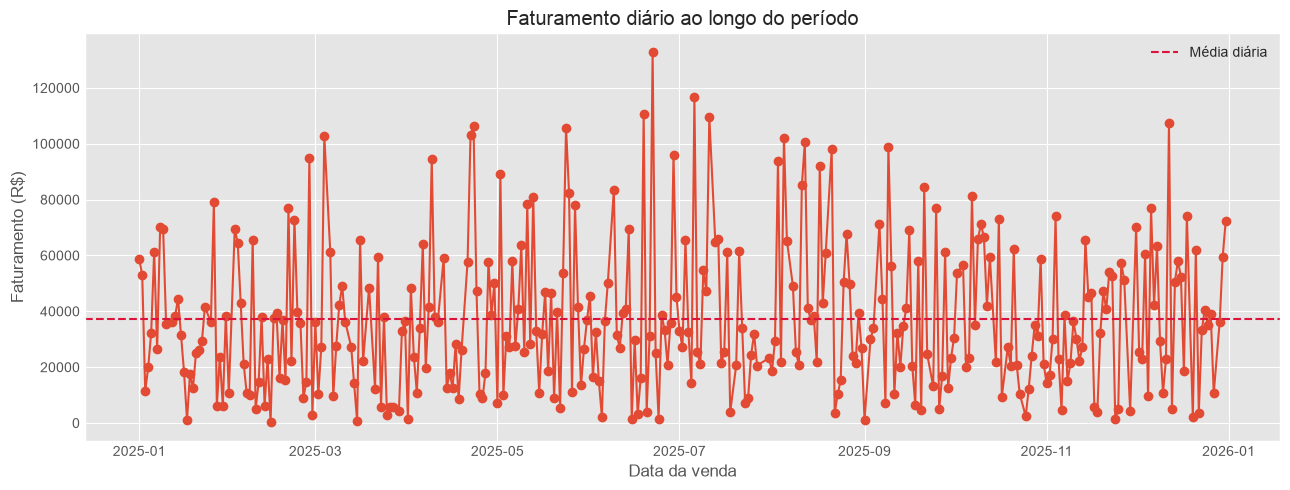

In [16]:
faturamento_diario = (
    vendas.groupby("data_venda", as_index=False)["valor_total"]
    .sum()
    .rename(columns={"valor_total": "faturamento_diario"})
)

faturamento_medio_diario = faturamento_diario["faturamento_diario"].mean()
print(f"Faturamento médio diário: R$ {faturamento_medio_diario:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(faturamento_diario["data_venda"], faturamento_diario["faturamento_diario"], marker="o")
ax.axhline(faturamento_medio_diario, color="crimson", linestyle="--", label="Média diária")
ax.set_title("Faturamento diário ao longo do período")
ax.set_xlabel("Data da venda")
ax.set_ylabel("Faturamento (R$)")
ax.legend()
fig.tight_layout()
plt.show()


**Interpretação:** a linha tracejada representa o faturamento médio diário. Datas acima dela contribuíram acima do desempenho típico do período, enquanto datas abaixo dela indicam oportunidades de investigação, como composição de produtos, quantidade vendida ou canal utilizado.

### 3.2 Distribuição por canal de venda e região

Os gráficos mostram a quantidade de vendas e o faturamento acumulado em cada canal e região. Assim, é possível distinguir volume de transações de geração de receita.

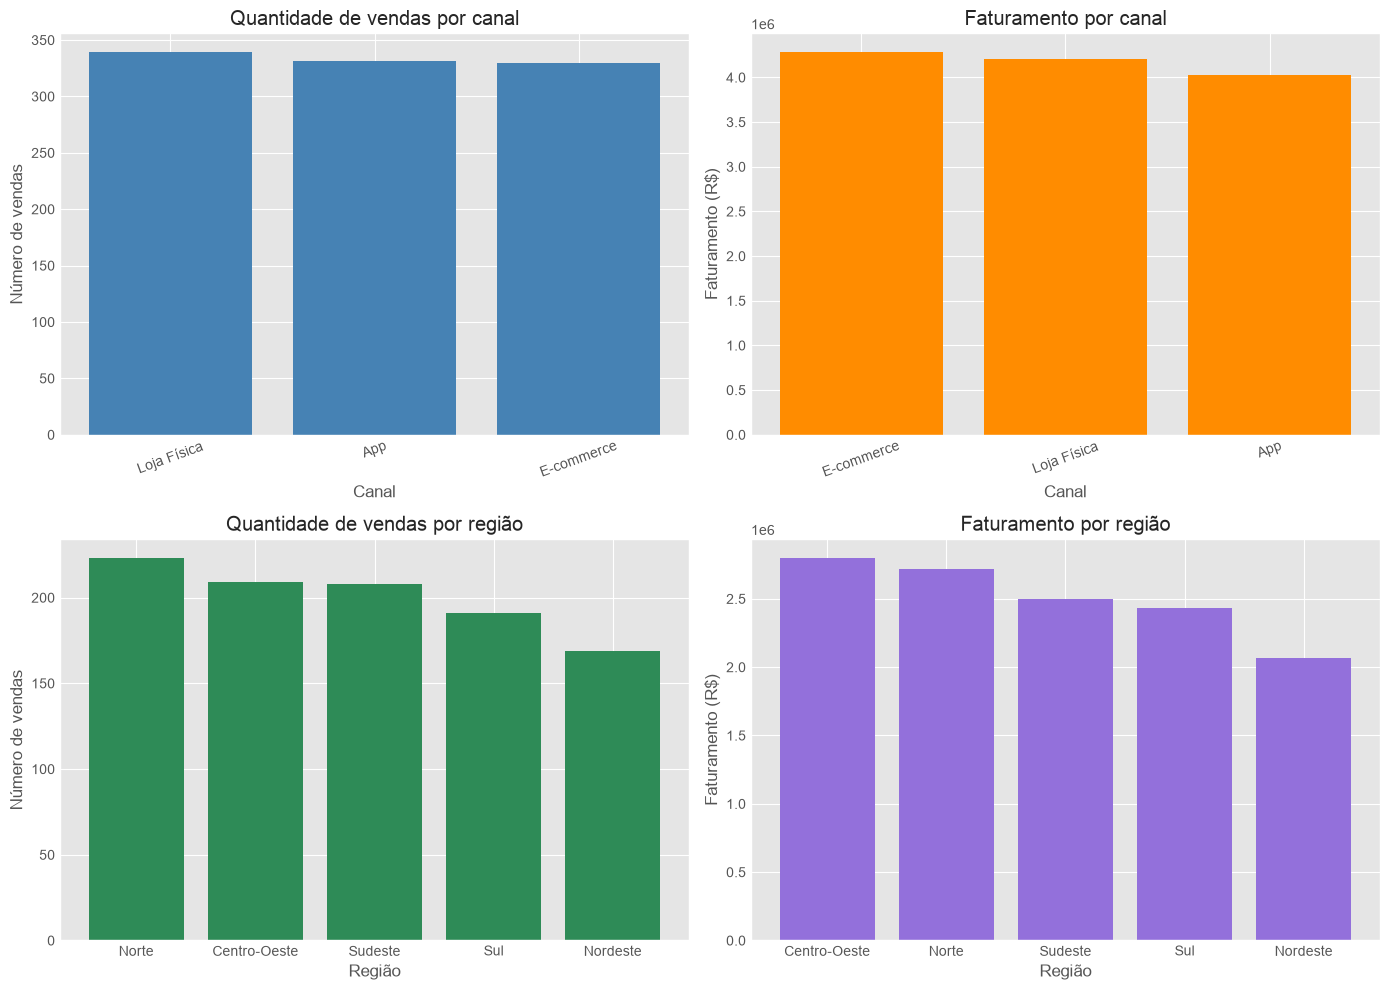

,canal_venda,valor_total
1,E-commerce,4279531.98
2,Loja Física,4210544.38
0,App,4022855.25


,regiao,valor_total
0,Centro-Oeste,2797119.63
2,Norte,2719091.90
3,Sudeste,2496766.63
4,Sul,2436197.54
1,Nordeste,2063755.91


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

contagem_canal = vendas["canal_venda"].value_counts()
axes[0, 0].bar(contagem_canal.index, contagem_canal.values, color="steelblue")
axes[0, 0].set_title("Quantidade de vendas por canal")
axes[0, 0].set_xlabel("Canal")
axes[0, 0].set_ylabel("Número de vendas")
axes[0, 0].tick_params(axis="x", rotation=20)

faturamento_canal = vendas.groupby("canal_venda", as_index=False)["valor_total"].sum().sort_values("valor_total", ascending=False)
axes[0, 1].bar(faturamento_canal["canal_venda"], faturamento_canal["valor_total"], color="darkorange")
axes[0, 1].set_title("Faturamento por canal")
axes[0, 1].set_xlabel("Canal")
axes[0, 1].set_ylabel("Faturamento (R$)")
axes[0, 1].tick_params(axis="x", rotation=20)

contagem_regiao = vendas["regiao"].value_counts()
axes[1, 0].bar(contagem_regiao.index, contagem_regiao.values, color="seagreen")
axes[1, 0].set_title("Quantidade de vendas por região")
axes[1, 0].set_xlabel("Região")
axes[1, 0].set_ylabel("Número de vendas")

faturamento_regiao = vendas.groupby("regiao", as_index=False)["valor_total"].sum().sort_values("valor_total", ascending=False)
axes[1, 1].bar(faturamento_regiao["regiao"], faturamento_regiao["valor_total"], color="mediumpurple")
axes[1, 1].set_title("Faturamento por região")
axes[1, 1].set_xlabel("Região")
axes[1, 1].set_ylabel("Faturamento (R$)")

plt.tight_layout()
plt.show()

display(faturamento_canal)
display(faturamento_regiao)


**Interpretação:** a comparação entre os painéis revela onde está concentrado o volume de vendas e onde está concentrado o faturamento. Um canal ou região com poucas transações, mas faturamento alto, pode ter maior valor médio por pedido; já o inverso pode indicar grande volume de pedidos de menor valor.

### 3.3 Categorias mais vendidas e margem de lucro média

,vendas,quantidade_total,faturamento,lucro_medio,margem_lucro_media
categoria_produto,,,,,
Beleza,210,2218,2524479.05,4121.59,35.60
Eletrodomésticos,205,2186,2744282.89,4735.93,35.28
Tecnologia,209,2106,2536064.90,4240.32,34.73
Alimentos,206,2093,2680083.63,4620.45,35.00
Moda,170,1752,2028021.14,4321.03,36.07


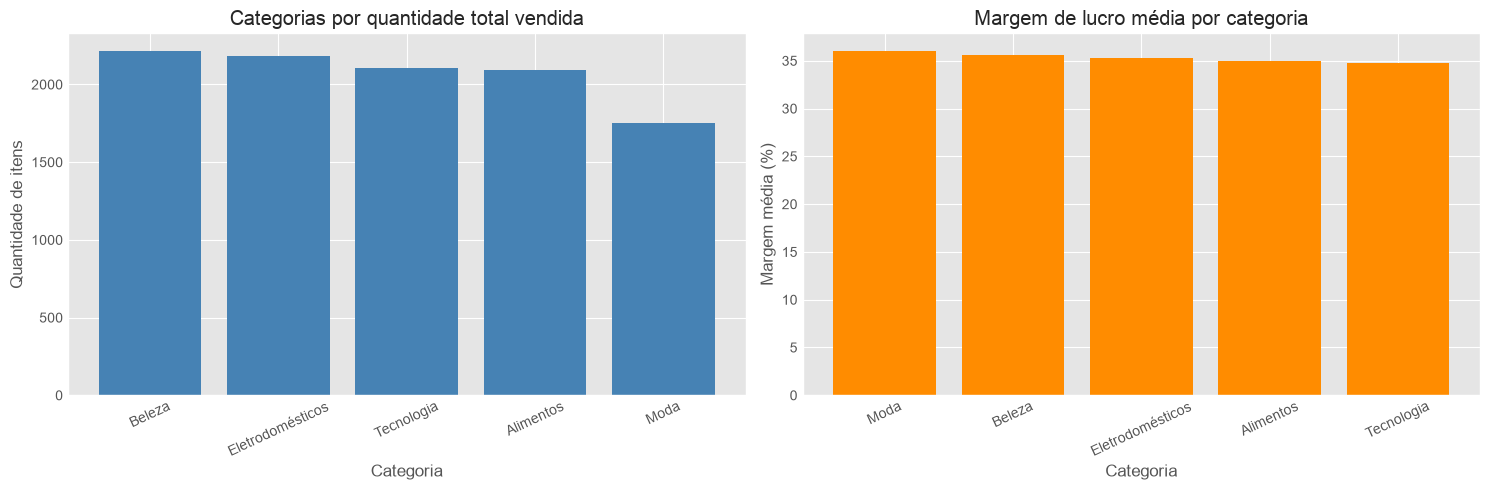

Categoria mais vendida em quantidade: Beleza
Categoria com maior margem média: Moda


In [18]:
categorias = (vendas.groupby("categoria_produto")
    .agg(vendas=("categoria_produto", "size"),
         quantidade_total=("quantidade", "sum"),
         faturamento=("valor_total", "sum"),
         lucro_medio=("lucro", "mean"),
         margem_lucro_media=("margem_lucro_%", "mean"))
    .sort_values("quantidade_total", ascending=False))

display(categorias)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
categorias_grafico = categorias.reset_index()
axes[0].bar(categorias_grafico["categoria_produto"], categorias_grafico["quantidade_total"], color="steelblue")
axes[0].set_title("Categorias por quantidade total vendida")
axes[0].set_xlabel("Categoria")
axes[0].set_ylabel("Quantidade de itens")
axes[0].tick_params(axis="x", rotation=25)

margens_grafico = categorias.reset_index().sort_values("margem_lucro_media", ascending=False)
axes[1].bar(margens_grafico["categoria_produto"], margens_grafico["margem_lucro_media"], color="darkorange")
axes[1].set_title("Margem de lucro média por categoria")
axes[1].set_xlabel("Categoria")
axes[1].set_ylabel("Margem média (%)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

categoria_mais_vendida = categorias["quantidade_total"].idxmax()
categoria_maior_margem = categorias["margem_lucro_media"].idxmax()
print(f"Categoria mais vendida em quantidade: {categoria_mais_vendida}")
print(f"Categoria com maior margem média: {categoria_maior_margem}")


**Interpretação:** a categoria mais vendida representa a maior demanda em volume, mas não necessariamente a maior rentabilidade. A margem média permite identificar categorias que preservam melhor o lucro proporcionalmente ao faturamento, apoiando decisões de preço, mix de produtos e campanhas.

### 3.4 Distribuição da satisfação do cliente

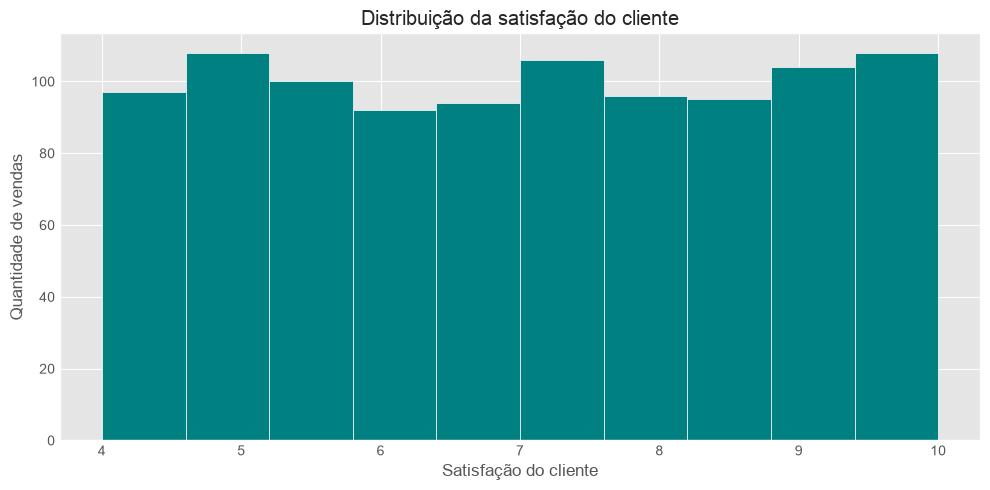

count   1000.00
mean       6.98
std        1.75
min        4.00
25%        5.40
50%        7.00
75%        8.50
max       10.00
Name: satisfacao_cliente, dtype: float64


In [19]:
plt.figure(figsize=(10, 5))
plt.hist(vendas["satisfacao_cliente"].dropna(), bins=10, color="teal", edgecolor="white")
plt.title("Distribuição da satisfação do cliente")
plt.xlabel("Satisfação do cliente")
plt.ylabel("Quantidade de vendas")
plt.tight_layout()
plt.show()

print(vendas["satisfacao_cliente"].describe())


**Interpretação:** o histograma mostra a concentração das avaliações e sua dispersão. Uma concentração em notas altas sugere boa experiência geral; uma distribuição espalhada ou com concentração em notas baixas indica que diferentes clientes podem estar vivenciando níveis distintos de serviço.

## 4. Análise diagnóstica

### 4.1 Correlações com o lucro

A correlação de Pearson varia de -1 a 1. Ela mede associação linear, mas não prova causalidade. Valores próximos de 1 indicam associação positiva; valores próximos de -1, associação negativa; e valores próximos de 0, pouca associação linear.

In [20]:
variaveis_diagnostico = ["lucro", "quantidade", "preco_unitario", "satisfacao_cliente"]
correlacoes = vendas[variaveis_diagnostico].corr()
display(correlacoes["lucro"].sort_values(ascending=False).to_frame("correlacao_com_lucro"))


,correlacao_com_lucro
lucro,1.00
preco_unitario,0.65
quantidade,0.57
satisfacao_cliente,-0.03


A associação mais forte com o lucro deve ser interpretada junto com a fórmula do lucro. Por exemplo, o valor total participa diretamente do cálculo do lucro, enquanto quantidade e preço unitário podem aumentar a receita, mas seus efeitos dependem do custo e da composição de cada venda.

### 4.2 Mapa de calor entre lucro, quantidade, preço e satisfação

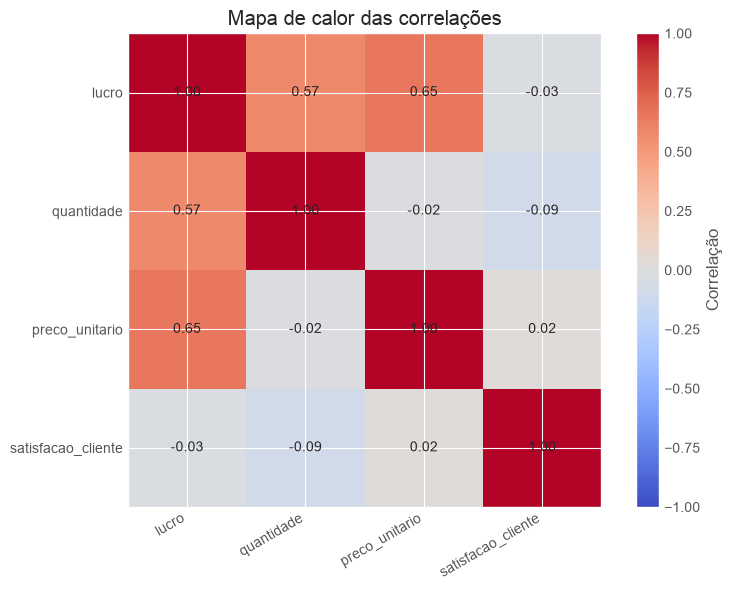

In [21]:
fig, ax = plt.subplots(figsize=(8, 6))
imagem = ax.imshow(correlacoes, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlacoes.columns)), correlacoes.columns, rotation=30, ha="right")
ax.set_yticks(range(len(correlacoes.index)), correlacoes.index)
for i in range(len(correlacoes.index)):
    for j in range(len(correlacoes.columns)):
        ax.text(j, i, f"{correlacoes.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(imagem, ax=ax, label="Correlação")
ax.set_title("Mapa de calor das correlações")
fig.tight_layout()
plt.show()


**Interpretação:** o mapa permite comparar simultaneamente os fatores associados. A diagonal apresenta correlação 1 porque cada variável é perfeitamente correlacionada consigo mesma. A leitura relevante está nas demais células, especialmente na linha/coluna do lucro.

### 4.3 Relação entre satisfação e valor total

Correlação entre satisfação e valor total: -0.03


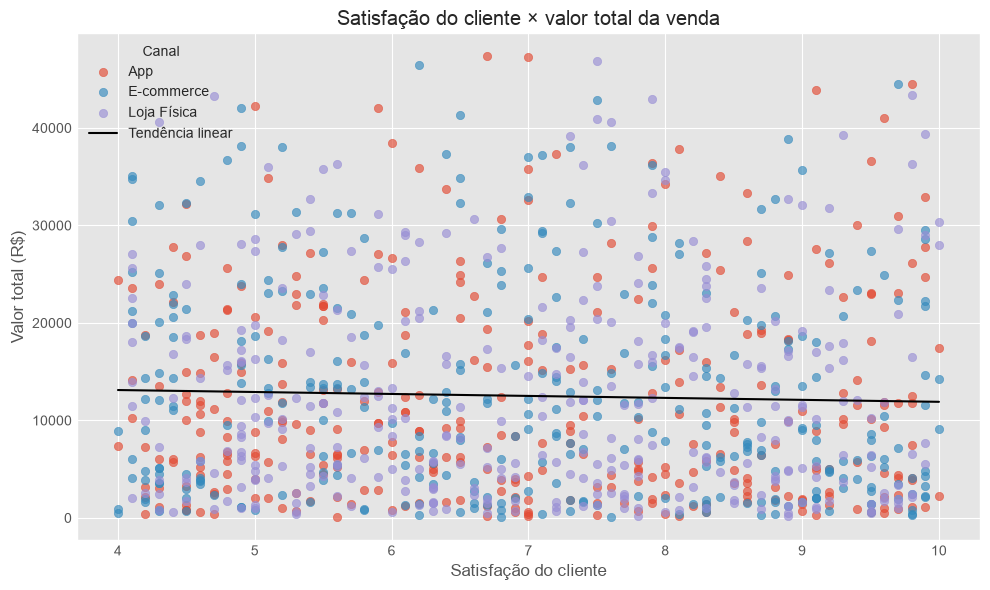

In [22]:
cor_satisfacao_valor = vendas[["satisfacao_cliente", "valor_total"]].corr().iloc[0, 1]
print(f"Correlação entre satisfação e valor total: {cor_satisfacao_valor:.2f}")

fig, ax = plt.subplots(figsize=(10, 6))
for canal, grupo in vendas.groupby("canal_venda"):
    ax.scatter(grupo["satisfacao_cliente"], grupo["valor_total"], alpha=0.65, label=canal)

x = vendas["satisfacao_cliente"].dropna()
y = vendas.loc[x.index, "valor_total"]
coeficientes = np.polyfit(x, y, 1)
linha_x = np.linspace(x.min(), x.max(), 100)
ax.plot(linha_x, np.polyval(coeficientes, linha_x), color="black", label="Tendência linear")
ax.set_title("Satisfação do cliente × valor total da venda")
ax.set_xlabel("Satisfação do cliente")
ax.set_ylabel("Valor total (R$)")
ax.legend(title="Canal")
fig.tight_layout()
plt.show()


**Interpretação:** o gráfico de dispersão permite verificar se vendas de maior valor tendem a apresentar avaliações maiores ou menores. A linha de tendência resume a direção média da associação, mas a dispersão dos pontos mostra se essa relação é consistente ou fraca.

## 5. Método dos 5 Porquês

A partir das correlações, gráficos e da diferença entre faturamento e custo, o problema gerencial investigado é: **por que o lucro varia entre as vendas?** Os 5 Porquês abaixo são uma hipótese diagnóstica baseada nos dados; correlação não permite afirmar causalidade sozinha.

1. **Por que o lucro varia?** Porque o valor total e o custo total não crescem na mesma proporção em todas as vendas.
2. **Por que valor e custo variam em proporções diferentes?** Porque as vendas combinam categorias, preços unitários, quantidades, canais e campanhas diferentes.
3. **Por que essa combinação altera o resultado?** Porque cada categoria e campanha pode ter uma margem média distinta, além de custos operacionais e descontos diferentes.
4. **Por que as margens distintas não são acompanhadas de forma uniforme?** Porque decisões de preço e campanha podem priorizar faturamento ou volume sem considerar a rentabilidade por venda.
5. **Por que decisões podem priorizar apenas volume?** Porque falta um acompanhamento integrado de margem, canal, categoria e satisfação para orientar as ações comerciais.

**Ações recomendadas:** acompanhar margem por categoria e canal em um painel periódico; revisar campanhas com margem abaixo da média; testar preços e descontos preservando a rentabilidade; e cruzar margem com satisfação para evitar que ações de curto prazo prejudiquem a experiência do cliente.

## 6. Conclusão

A análise descritiva apresenta o faturamento médio diário, a distribuição das vendas por canal e região, as categorias de maior volume e margem e o comportamento da satisfação. A análise diagnóstica complementa esses resultados ao investigar associações lineares entre lucro, quantidade, preço e satisfação. Em conjunto, os resultados apoiam decisões baseadas em evidências, mas eventuais relações causais devem ser confirmadas com análises adicionais, como comparação entre períodos, controle por categoria e testes de campanhas.